# Customer Churn Exploration

We will load the IBM Telco Customer Churn data, inspect its structure and data quality, understand the **Churn** outcome, and create charts to look for useful patterns. The goal is to understand the data before building a predictive model.

## What is customer churn?

Customer churn happens when a customer stops using a company's product or service. In this dataset, `Churn` records whether a customer left. A business may use churn analysis to identify customer groups that could benefit from better support or service.

We will first examine the data as collected. We will not train a model in this exploration notebook.

## 1. Load the dataset

The CSV is the public sample distributed in IBM's archived [Telco Customer Churn repository](https://github.com/IBM/telco-customer-churn-on-icp4d), under `data/Telco-Customer-Churn.csv`. It is saved locally at `data/raw/Telco-Customer-Churn.csv` so the notebook can work without downloading it each time.

We try both the project-root and notebook-folder relative paths because Jupyter may start its working directory in either place.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

candidate_paths = [
    Path("data/raw/Telco-Customer-Churn.csv"),
    Path("../data/raw/Telco-Customer-Churn.csv"),
]
data_path = next((path for path in candidate_paths if path.is_file()), None)

if data_path is None:
    searched_paths = ", ".join(str(path) for path in candidate_paths)
    raise FileNotFoundError(f"Could not find the dataset. Checked: {searched_paths}")

df = pd.read_csv(data_path)
print(f"Loaded {data_path}")
display(df.head())

Loaded ..\data\raw\Telco-Customer-Churn.csv


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Check the dataset's size and columns

The shape tells us how many customer records and variables are available. Listing the column names helps us see what customer, service, billing, and outcome information we can explore.

In [2]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
display(pd.DataFrame({"Column": df.columns}))

Rows: 7,043
Columns: 21


,Column
0,customerID
1,gender
2,SeniorCitizen
3,Partner
4,Dependents
5,tenure
6,PhoneService
7,MultipleLines
8,InternetService
9,OnlineSecurity


## 3. Inspect data types

Data types affect which summaries and charts are appropriate. For example, tenure and charges should be numeric, while fields such as contract type and churn are categories. `info()` also gives a quick non-null count for each column.

In [3]:
df.info()
display(df.dtypes.rename("data type").to_frame())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,data type
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


## 4. Check for missing and blank values

A missing value can be stored as a true null or as a string containing only spaces. We count both forms so whitespace-only entries are not mistaken for valid data. This distinction matters because the source CSV stores some `TotalCharges` entries as spaces.

In [4]:
blank_strings = df.astype("string").apply(
    lambda column: column.str.fullmatch(r"\s*").fillna(False).sum()
)
missing_summary = pd.DataFrame(
    {
        "Missing values": df.isna().sum(),
        "Whitespace-only strings": blank_strings,
    }
)
display(missing_summary.loc[missing_summary.sum(axis=1).gt(0)])

,Missing values,Whitespace-only strings
TotalCharges,0,11


### Make `TotalCharges` numeric for later analysis

The whitespace-only `TotalCharges` entries represent unavailable totals (for example, customers with zero months of tenure). We convert those strings to missing values, then parse the remaining entries as numbers. This preserves the information that those totals are unknown instead of treating spaces as a number.

In [5]:
blank_total_charges = df["TotalCharges"].astype("string").str.fullmatch(r"\s*").fillna(False)
df.loc[blank_total_charges, "TotalCharges"] = pd.NA
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="raise")

print(f"TotalCharges values made missing: {blank_total_charges.sum()}")
print(f"TotalCharges data type after conversion: {df['TotalCharges'].dtype}")

TotalCharges values made missing: 11
TotalCharges data type after conversion: float64


## 5. Explore the churn target

First, count customers in each target class and calculate each class's share of the dataset. The shares show the baseline outcome mix; they are not a model's accuracy.

In [6]:
churn_counts = df["Churn"].value_counts().reindex(["No", "Yes"], fill_value=0)
churn_summary = pd.DataFrame(
    {
        "Customers": churn_counts,
        "Share (%)": churn_counts.div(len(df)).mul(100),
    }
)
display(churn_summary.round({"Share (%)": 1}))

,Customers,Share (%)
Churn,,
No,5174,73.5
Yes,1869,26.5


### Visualize the target balance

A labeled bar chart makes the class sizes easy to compare. If one outcome is much less common, later model evaluation should consider more than overall accuracy.

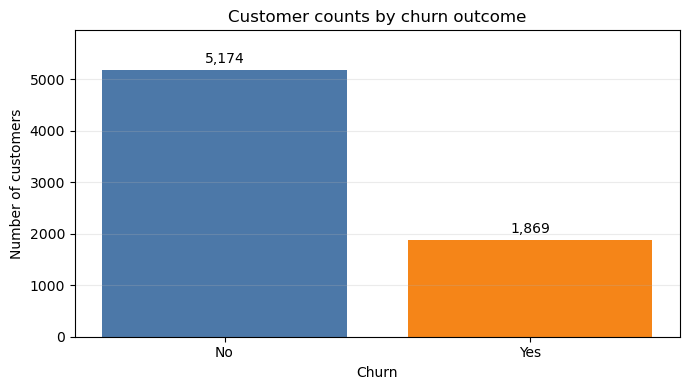

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(churn_counts.index, churn_counts.values, color=["#4C78A8", "#F58518"])
ax.bar_label(bars, fmt="{:,.0f}", padding=3)
ax.set_title("Customer counts by churn outcome")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of customers")
ax.set_ylim(0, churn_counts.max() * 1.15)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

## 6. Compare churn rates across contract types

For each contract type, calculate the percentage of customers whose `Churn` value is `Yes`. Comparing rates (rather than raw counts) helps account for groups of different sizes. This is a descriptive comparison, not evidence that the contract type causes churn.

,Churn rate (%)
Contract,
Two year,2.8
One year,11.3
Month-to-month,42.7


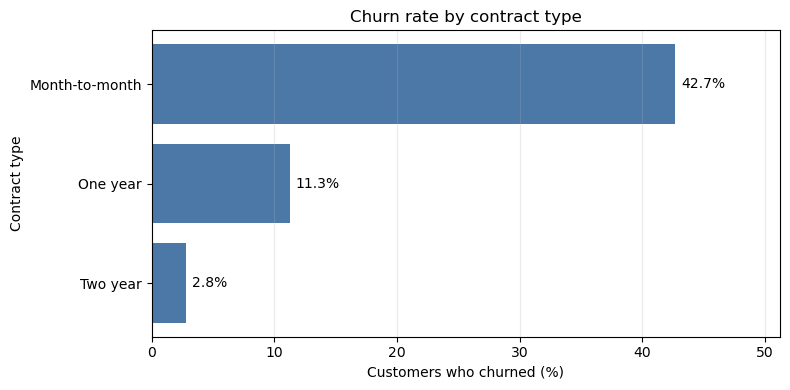

In [8]:
contract_churn_rate = (
    df.groupby("Contract")["Churn"]
    .apply(lambda values: values.eq("Yes").mean() * 100)
    .sort_values()
)
display(contract_churn_rate.rename("Churn rate (%)").round(1).to_frame())

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(contract_churn_rate.index, contract_churn_rate.values, color="#4C78A8")
ax.bar_label(bars, fmt="%.1f%%", padding=4)
ax.set_title("Churn rate by contract type")
ax.set_xlabel("Customers who churned (%)")
ax.set_ylabel("Contract type")
ax.set_xlim(0, contract_churn_rate.max() * 1.2)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

## 7. Compare tenure and monthly charges by churn

These boxplots show the median and spread of two numeric customer measures for each churn outcome. Look for differences worth investigating, but remember that these charts describe association and do not establish a cause.

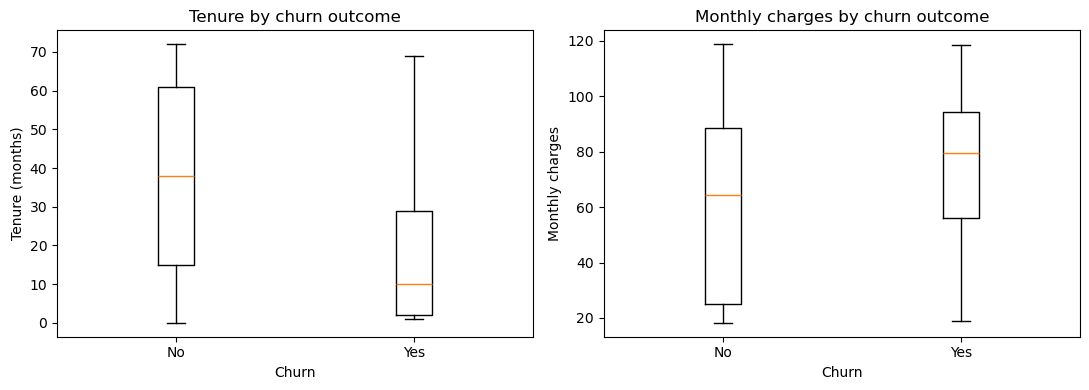

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

tenure_groups = [df.loc[df["Churn"].eq(label), "tenure"] for label in ["No", "Yes"]]
axes[0].boxplot(tenure_groups, tick_labels=["No", "Yes"], showfliers=False)
axes[0].set_title("Tenure by churn outcome")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Tenure (months)")

charge_groups = [df.loc[df["Churn"].eq(label), "MonthlyCharges"] for label in ["No", "Yes"]]
axes[1].boxplot(charge_groups, tick_labels=["No", "Yes"], showfliers=False)
axes[1].set_title("Monthly charges by churn outcome")
axes[1].set_xlabel("Churn")
axes[1].set_ylabel("Monthly charges")

fig.tight_layout()
plt.show()

## Exploration checkpoint

We have confirmed the dataset's dimensions and fields, checked data types and missing/blank entries, and described the churn balance. The charts compare churn with contract type, tenure, and monthly charges. Treat these patterns as questions to investigate further—not as proof of causes or predictions. A later notebook can build a model after choosing a validation strategy and suitable evaluation metrics.

## 8. Prepare a reproducible train/test split

Reload the source data so preprocessing starts from the raw values. Convert whitespace-only `TotalCharges` entries to missing values and then to numeric values. The customer ID is kept in the source table but excluded from the feature set because it identifies records rather than describing customer attributes.

In [10]:
from sklearn.model_selection import train_test_split

preprocessing_df = pd.read_csv(data_path)
blank_total_charges = preprocessing_df["TotalCharges"].astype("string").str.fullmatch(r"\s*").fillna(False)
preprocessing_df.loc[blank_total_charges, "TotalCharges"] = pd.NA
preprocessing_df["TotalCharges"] = pd.to_numeric(preprocessing_df["TotalCharges"], errors="raise")

print(f"Whitespace-only TotalCharges values converted to missing: {int(blank_total_charges.sum())}")
missingness = preprocessing_df.isna().sum().rename("Missing values")
display(missingness.loc[missingness.gt(0)].to_frame())

churn = preprocessing_df["Churn"].map({"No": 0, "Yes": 1})
if churn.isna().any():
    raise ValueError("Churn contains values other than 'No' and 'Yes'.")
y = churn.astype("int8")
X = preprocessing_df.drop(columns=["Churn", "customerID"])
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"Numeric features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")

Whitespace-only TotalCharges values converted to missing: 11


,Missing values
TotalCharges,11


Numeric features (4): ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 9. Fit preprocessing on training data only

Numeric columns use median imputation. Categorical columns use most-frequent imputation followed by one-hot encoding; unknown categories at transform time are ignored. The test split is transformed with the fitted training pipeline and is not used to fit any preprocessing step.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

numeric_pipeline = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median"))]
)
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore")),
    ]
)
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ]
)

X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

print(
    f"Training features: {X_train_transformed.shape[0]:,} samples x "
    f"{X_train_transformed.shape[1]:,} transformed features"
)
print(
    f"Test features: {X_test_transformed.shape[0]:,} samples x "
    f"{X_test_transformed.shape[1]:,} transformed features"
)
print(f"Training target samples: {len(y_train):,}")
print(f"Test target samples: {len(y_test):,}")

target_proportions = pd.DataFrame(
    {
        "Train (%)": y_train.value_counts(normalize=True).sort_index(),
        "Test (%)": y_test.value_counts(normalize=True).sort_index(),
    }
).rename(index={0: "No (0)", 1: "Yes (1)"}).mul(100)
display(target_proportions.round(2))

assert X_train_transformed.shape[0] == len(y_train)
assert X_test_transformed.shape[0] == len(y_test)
assert X_train_transformed.shape[1] == X_test_transformed.shape[1]

Training features: 5,634 samples x 45 transformed features
Test features: 1,409 samples x 45 transformed features
Training target samples: 5,634
Test target samples: 1,409


,Train (%),Test (%)
Churn,,
No (0),73.46,73.46
Yes (1),26.54,26.54
